# Lab 3 — Exploratory Data Analysis (EDA)

**Dataset:** Insurance Dataset

### Objectives
- Perform descriptive statistics
- Visualize data using histograms
- Create scatter plots
- Create box plots
- Create a correlation heatmap
- Create pair plots
- Analyze categorical variables
- Write observations from the EDA


In [20]:
# Cell 1 — Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")


In [21]:
from pathlib import Path

# Cell 2 — Load dataset

# Try likely locations for the dataset
candidate_paths = [
    Path.cwd() / "insurance.csv",            # current notebook folder
    Path.cwd().parent / "insurance.csv",     # parent folder
    Path("C:/Users/saini/Downloads/insurance.csv"),  # common download folder
    Path("insurance.csv")                    # relative path
]

for path in candidate_paths:
    if path.exists():
        df = pd.read_csv(path)
        break
else:
    raise FileNotFoundError(
        "insurance.csv not found. Please place the file in the notebook folder or update the path."
    )

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


In [23]:
# Cell 4 — Descriptive statistics

display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
age,"1,338.00",39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,"1,338.00",30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,"1,338.00",1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,"1,338.00","13,270.42","12,110.01","1,121.87","4,740.29","9,382.03","16,639.91","63,770.43"


In [24]:
# Cell 5 — Missing values and duplicates

print("Missing values:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values: 0
Duplicate rows: 1


## 1. Histograms

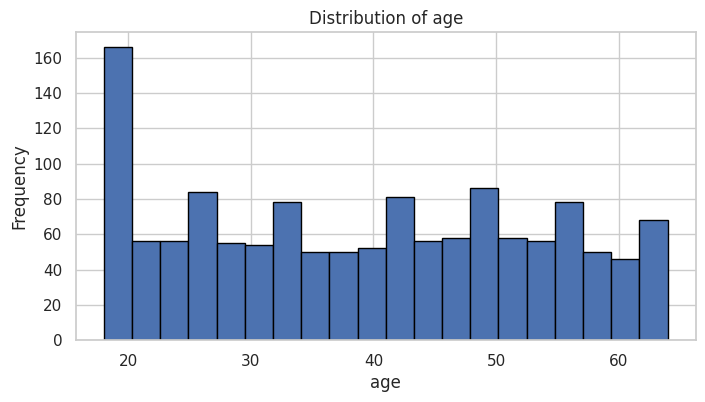

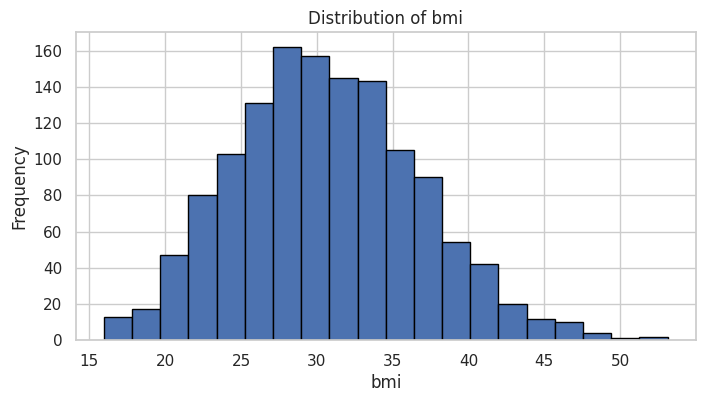

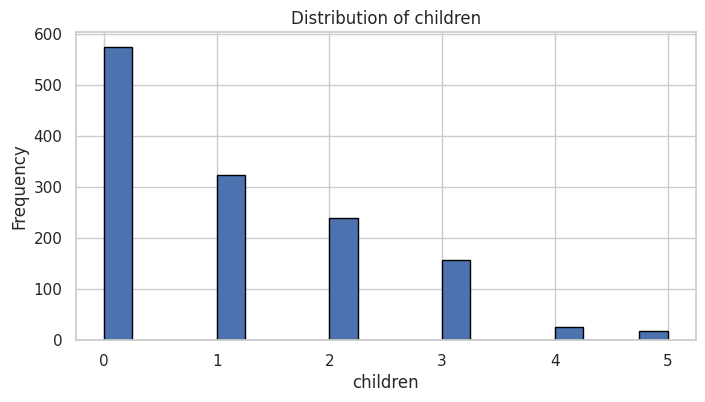

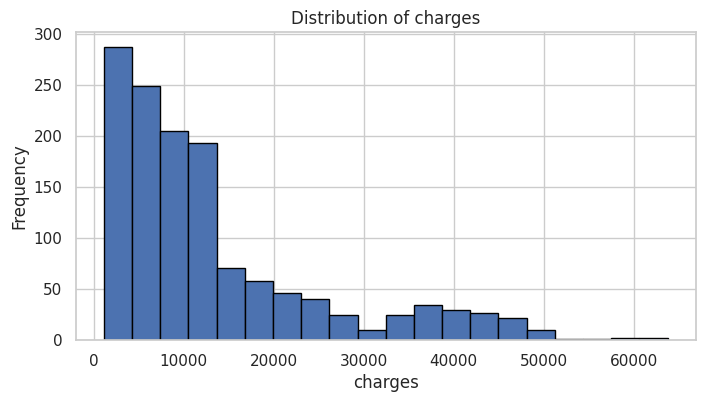

In [26]:
# Cell 7 — Histograms for all numerical columns

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=20, edgecolor="black")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {col}")
    plt.show()


## 2. Scatter plots

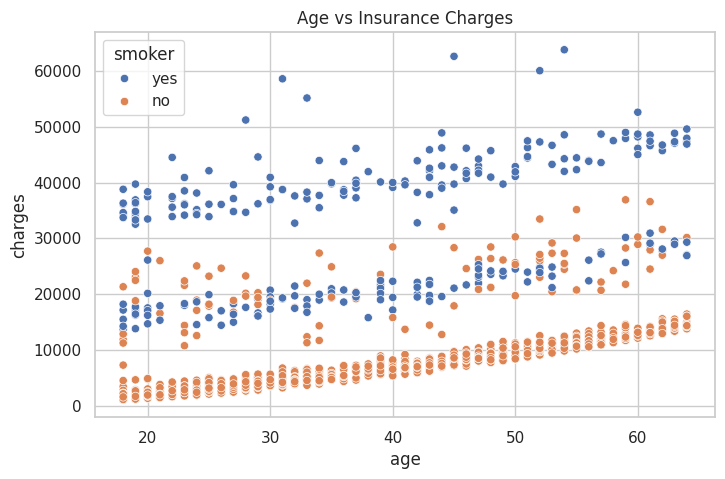

In [27]:
# Cell 8 — Age vs charges

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs Insurance Charges")
plt.show()


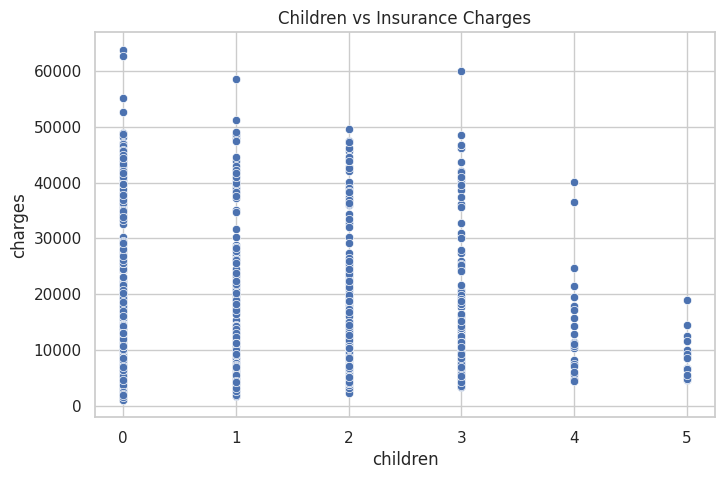

In [29]:
# Cell 10 — Children vs charges

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="children", y="charges")
plt.title("Children vs Insurance Charges")
plt.show()


## 3. Box plots

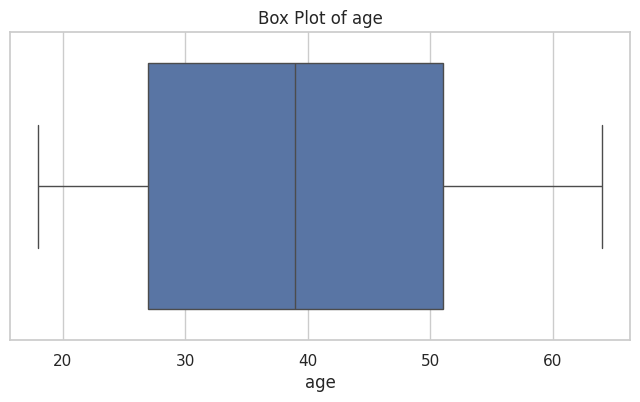

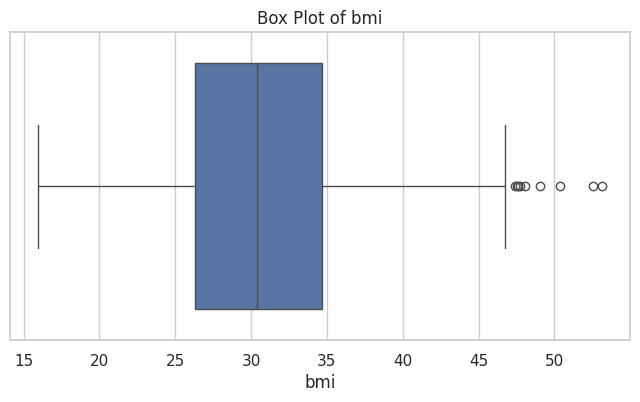

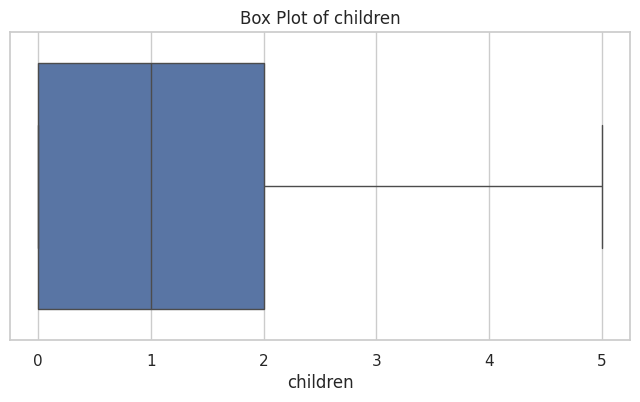

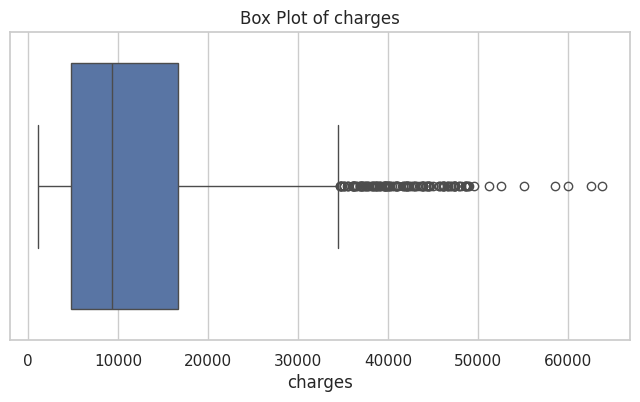

In [30]:
# Cell 11 — Box plots for numerical columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.show()


## 4. Correlation heatmap

In [33]:
# Cell 14 — Correlation matrix

corr = df.select_dtypes(include=np.number).corr()
display(corr)


,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


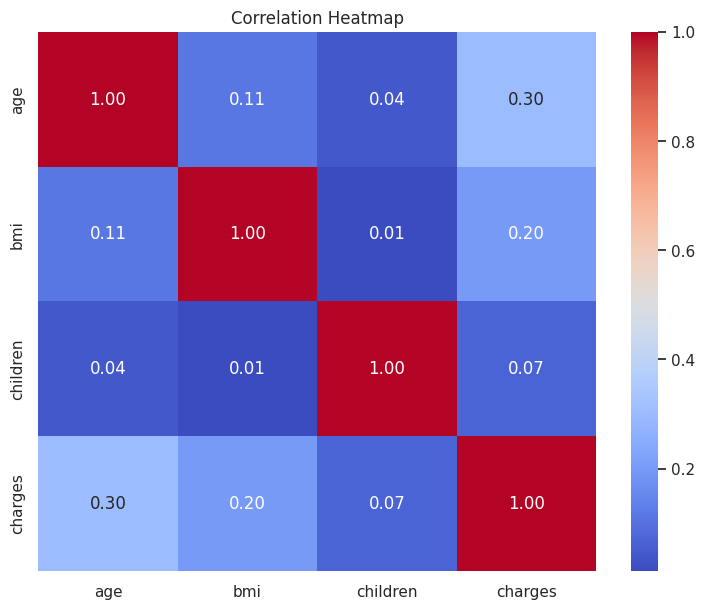

In [34]:
# Cell 15 — Correlation heatmap

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


## 5. Categorical analysis

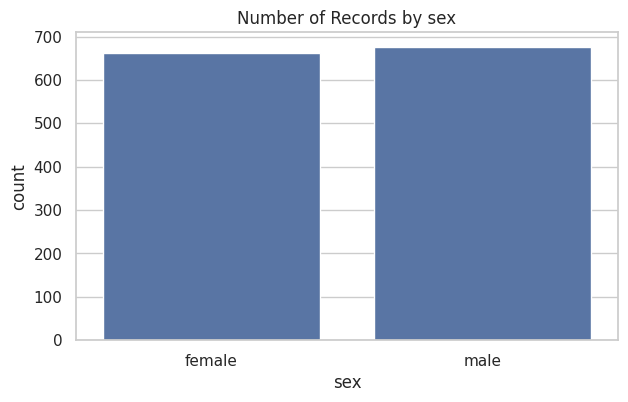

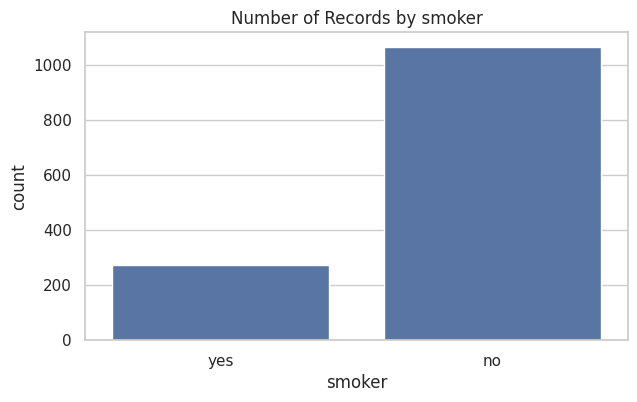

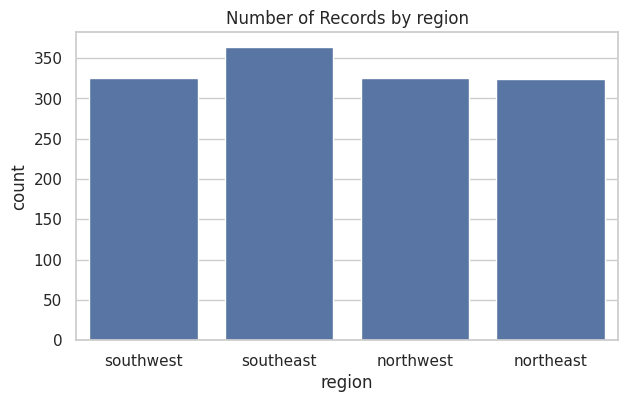

In [35]:
# Cell 17 — Count plots

for col in ["sex", "smoker", "region"]:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col)
    plt.title(f"Number of Records by {col}")
    plt.show()


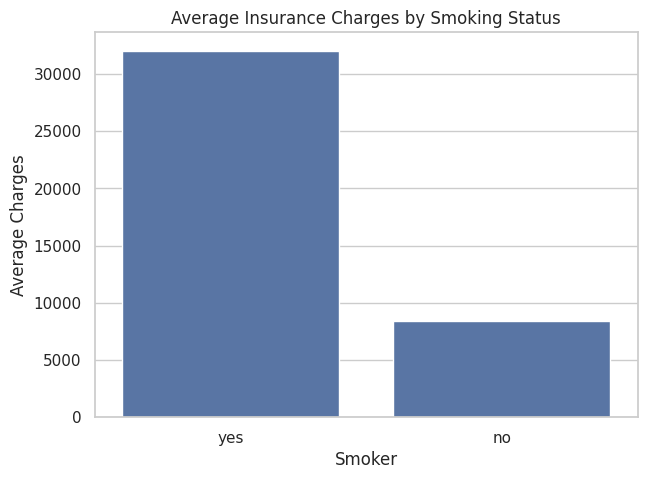

smoker
yes   32,050.23
no     8,434.27
Name: charges, dtype: float64

In [36]:
# Cell 18 — Average charges by smoker

avg_smoker = df.groupby("smoker")["charges"].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(x=avg_smoker.index, y=avg_smoker.values)
plt.title("Average Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Average Charges")
plt.show()

display(avg_smoker)
